In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/batooljuaitem/predict-students-dropout-and-academic-success/data.csv


In [2]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [3]:
# Load dataset
df = pd.read_csv(
    '/kaggle/input/datasets/batooljuaitem/predict-students-dropout-and-academic-success/data.csv',
    sep=';'
)

df.columns = df.columns.str.strip()

# Separate features and target
X = df.drop(columns=['Target'])
y = df['Target']

print("Dataset Shape:", df.shape)
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Dataset Shape: (4424, 37)
Features Shape: (4424, 36)
Target Shape: (4424,)


In [4]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (3539, 36)
Testing Data: (885, 36)


In [5]:
# Experiment 1: Different numbers of trees

n_estimators_values = [100, 200, 300]

for n in n_estimators_values:

    model = RandomForestClassifier(
        n_estimators=n,
        random_state=42
    )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    print(f"\nNumber of Trees: {n}")
    print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
    print("F1-Score:", round(f1_score(y_test, y_pred, average='macro'), 4))


Number of Trees: 100
Accuracy: 0.7672
F1-Score: 0.6916

Number of Trees: 200
Accuracy: 0.765
F1-Score: 0.6819

Number of Trees: 300
Accuracy: 0.7672
F1-Score: 0.6865


In [6]:
# Experiment 2: Different maximum depths

depth_values = [5, 10, 20, None]

for depth in depth_values:

    model = RandomForestClassifier(
        n_estimators=100,
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    print(f"\nMax Depth: {depth}")
    print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
    print("F1-Score:", round(f1_score(y_test, y_pred, average='macro'), 4))


Max Depth: 5
Accuracy: 0.7537
F1-Score: 0.6133

Max Depth: 10
Accuracy: 0.7684
F1-Score: 0.6831

Max Depth: 20
Accuracy: 0.765
F1-Score: 0.6873

Max Depth: None
Accuracy: 0.7672
F1-Score: 0.6916


In [7]:
# Experiment 3: Different min_samples_split values

split_values = [2, 5, 10, 20]

for value in split_values:

    model = RandomForestClassifier(
        n_estimators=100,
        min_samples_split=value,
        random_state=42
    )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    print(f"\nMin Samples Split: {value}")
    print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
    print("F1-Score:", round(f1_score(y_test, y_pred, average='macro'), 4))


Min Samples Split: 2
Accuracy: 0.7672
F1-Score: 0.6916

Min Samples Split: 5
Accuracy: 0.7661
F1-Score: 0.6856

Min Samples Split: 10
Accuracy: 0.7718
F1-Score: 0.6904

Min Samples Split: 20
Accuracy: 0.7661
F1-Score: 0.6792


In [8]:
# Experiment 4: Different max_features values

feature_values = ['sqrt', 'log2', None]

for value in feature_values:

    model = RandomForestClassifier(
        n_estimators=100,
        max_features=value,
        random_state=42
    )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    print(f"\nMax Features: {value}")
    print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
    print("F1-Score:", round(f1_score(y_test, y_pred, average='macro'), 4))


Max Features: sqrt
Accuracy: 0.7672
F1-Score: 0.6916

Max Features: log2
Accuracy: 0.7763
F1-Score: 0.6974

Max Features: None
Accuracy: 0.7492
F1-Score: 0.6769


In [9]:
# Experiment 5: Different class weights

weight_values = [None, 'balanced']

for value in weight_values:

    model = RandomForestClassifier(
        n_estimators=100,
        class_weight=value,
        random_state=42
    )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    print(f"\nClass Weight: {value}")
    print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
    print("F1-Score:", round(f1_score(y_test, y_pred, average='macro'), 4))


Class Weight: None
Accuracy: 0.7672
F1-Score: 0.6916

Class Weight: balanced
Accuracy: 0.7774
F1-Score: 0.6963


In [10]:
# Summary of the five optimization experiments

experiments_summary = pd.DataFrame({
    'Experiment': [
        'n_estimators',
        'max_depth',
        'min_samples_split',
        'max_features',
        'class_weight'
    ],
    'Best Setting': [
        '100',
        'None',
        '2',
        'log2',
        'balanced'
    ],
    'Accuracy': [
        0.7672,
        0.7672,
        0.7672,
        0.7763,
        0.7774
    ],
    'F1-Score': [
        0.6916,
        0.6916,
        0.6916,
        0.6974,
        0.6963
    ]
})

print(experiments_summary)

          Experiment Best Setting  Accuracy  F1-Score
0       n_estimators          100    0.7672    0.6916
1          max_depth         None    0.7672    0.6916
2  min_samples_split            2    0.7672    0.6916
3       max_features         log2    0.7763    0.6974
4       class_weight     balanced    0.7774    0.6963


In [11]:
# Create optimized Random Forest model
optimized_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    min_samples_split=2,
    max_features='log2',
    class_weight='balanced',
    random_state=42
)

# Train the optimized model
optimized_model.fit(X_train, y_train)

# Make predictions
optimized_pred = optimized_model.predict(X_test)

print("Optimized Random Forest Model Trained Successfully!")

Optimized Random Forest Model Trained Successfully!


In [12]:
# Evaluate optimized model
optimized_accuracy = accuracy_score(y_test, optimized_pred)
optimized_precision = precision_score(y_test, optimized_pred, average='macro')
optimized_recall = recall_score(y_test, optimized_pred, average='macro')
optimized_f1 = f1_score(y_test, optimized_pred, average='macro')

print("Optimized Random Forest Results")
print("--------------------------------")
print("Accuracy:", round(optimized_accuracy, 4))
print("Precision:", round(optimized_precision, 4))
print("Recall:", round(optimized_recall, 4))
print("F1-Score:", round(optimized_f1, 4))

Optimized Random Forest Results
--------------------------------
Accuracy: 0.7706
Precision: 0.7218
Recall: 0.6794
F1-Score: 0.6902


In [13]:
# Recreate baseline model
baseline_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

baseline_model.fit(X_train, y_train)

# Make baseline predictions
baseline_pred = baseline_model.predict(X_test)

# Calculate baseline metrics
accuracy = accuracy_score(y_test, baseline_pred)
precision = precision_score(y_test, baseline_pred, average='macro')
recall = recall_score(y_test, baseline_pred, average='macro')
f1 = f1_score(y_test, baseline_pred, average='macro')

print("Baseline Results Calculated Successfully!")

Baseline Results Calculated Successfully!


In [14]:
# Compare baseline and optimized models

comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Baseline': [accuracy, precision, recall, f1],
    'Optimized': [
        optimized_accuracy,
        optimized_precision,
        optimized_recall,
        optimized_f1
    ]
})

print(comparison)

      Metric  Baseline  Optimized
0   Accuracy  0.767232   0.770621
1  Precision  0.721395   0.721795
2     Recall  0.680208   0.679367
3   F1-Score  0.691628   0.690185


In [15]:
# 5-Fold Cross Validation
cv_scores = cross_val_score(
    optimized_model,
    X,
    y,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

print("Cross Validation Scores:", np.round(cv_scores, 4))
print("Mean CV F1:", round(cv_scores.mean(), 4))
print("Standard Deviation:", round(cv_scores.std(), 4))

Cross Validation Scores: [0.6741 0.6852 0.7059 0.6974 0.6891]
Mean CV F1: 0.6903
Standard Deviation: 0.0108


In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

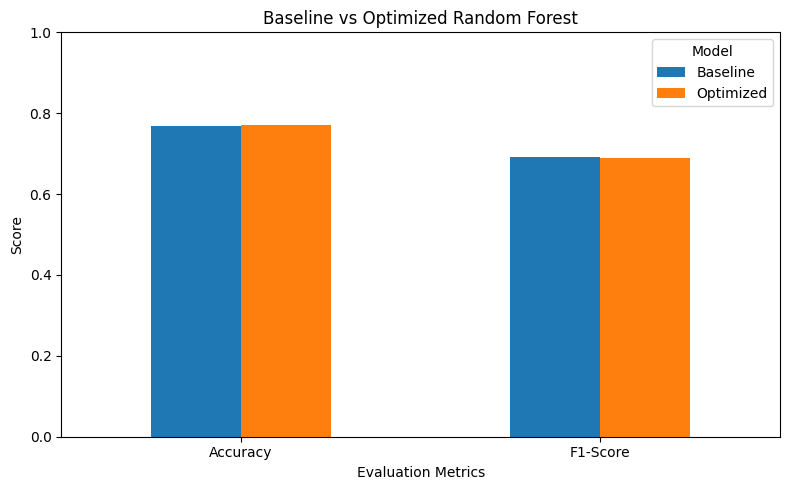

In [17]:
# Compare Baseline and Optimized models

comparison_plot = comparison.set_index('Metric')[['Baseline', 'Optimized']]

comparison_plot.loc[['Accuracy', 'F1-Score']].plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Baseline vs Optimized Random Forest')
plt.ylabel('Score')
plt.xlabel('Evaluation Metrics')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title='Model')
plt.tight_layout()
plt.show()

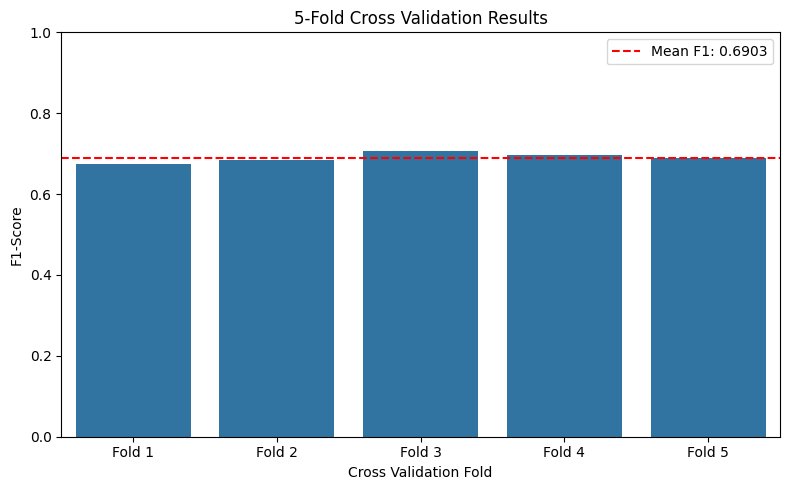

In [18]:
# Plot Cross Validation Scores

plt.figure(figsize=(8, 5))

sns.barplot(
    x=[f'Fold {i}' for i in range(1, 6)],
    y=cv_scores
)

plt.axhline(
    y=cv_scores.mean(),
    linestyle='--',
    color='red',
    label=f'Mean F1: {cv_scores.mean():.4f}'
)

plt.title('5-Fold Cross Validation Results')
plt.xlabel('Cross Validation Fold')
plt.ylabel('F1-Score')
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()